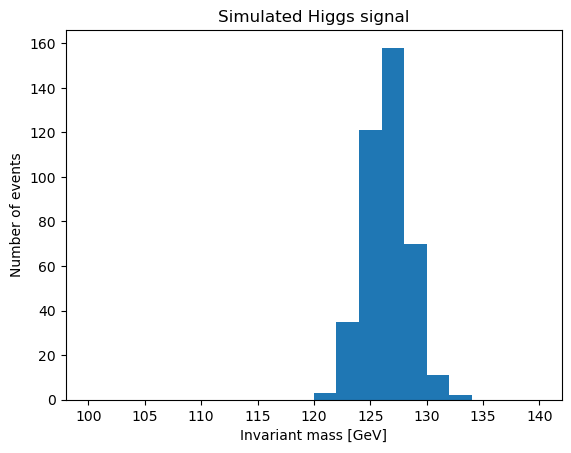

In [2]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

# One year of signal data
n_signal = 400
mu = 126.5
sigma = 2.0

signal = rng.normal(mu, sigma, n_signal)

# Mass window
m_min = 100
m_max = 140

# Keep events in the allowed mass window
signal = signal[(signal >= m_min) & (signal <= m_max)]

# Histogram
plt.hist(signal, bins=20, range=(m_min, m_max))
plt.xlabel("Invariant mass [GeV]")
plt.ylabel("Number of events")
plt.title("Simulated Higgs signal")
plt.show()


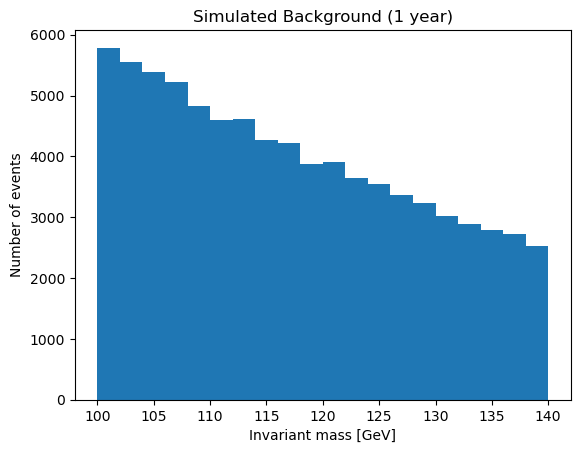

In [3]:

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

alpha = 0.0218
m_min = 100
m_max = 140
n_background = 80000

# Step 1: Generate uniform random numbers
u = rng.uniform(0, 1, n_background)

# Step 2: Inverse transform method
background = m_min - np.log(
    1 - u * (1 - np.exp(-alpha * (m_max - m_min)))
) / alpha

# Step 3: Plot histogram
plt.hist(background, bins=20, range=(100, 140))
plt.xlabel("Invariant mass [GeV]")
plt.ylabel("Number of events")
plt.title("Simulated Background (1 year)")
plt.show()


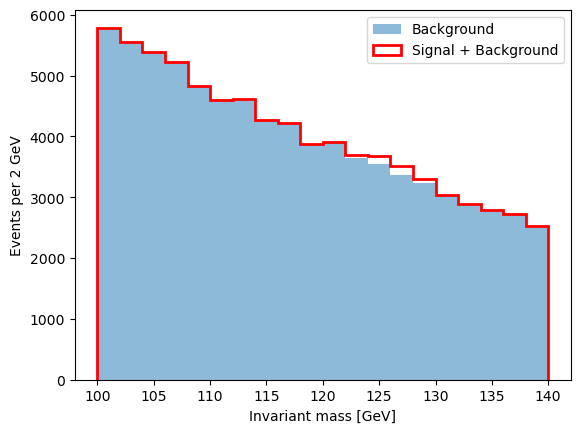

In [4]:

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

# Parameters
alpha = 0.0218
mu = 126.5
sigma = 2.0

n_signal = 400
n_background = 80000

m_min = 100
m_max = 140

# Generate background
u = rng.uniform(0, 1, n_background)

background = m_min - np.log(
    1 - u * (1 - np.exp(-alpha * (m_max - m_min)))
) / alpha

# Generate signal
signal = rng.normal(mu, sigma, n_signal)

# Combine signal and background
data = np.concatenate([background, signal])

# Histogram with 20 bins
bins = np.linspace(100, 140, 21)

plt.hist(background, bins=bins, alpha=0.5,
         label="Background")
plt.hist(data, bins=bins, histtype="step",
         color="red", linewidth=2,
         label="Signal + Background")

plt.xlabel("Invariant mass [GeV]")
plt.ylabel("Events per 2 GeV")
plt.legend()
plt.show()


In [5]:

# Observed counts (Signal + Background)
observed, edges = np.histogram(data, bins=bins)

# Expected counts under H0 (Background only)
a = edges[:-1]
b = edges[1:]

probabilities = (
    np.exp(-alpha * (a - m_min))
    - np.exp(-alpha * (b - m_min))
) / (1 - np.exp(-alpha * (m_max - m_min)))

expected = n_background * probabilities

print("Bin | Observed | Expected")
for i in range(20):
    print(f"{i+1:3d} | {observed[i]:8d} | {expected[i]:8.2f}")

print("Total expected:", expected.sum())
print("Total observed:", observed.sum())


Bin | Observed | Expected
  1 |     5786 |  5865.51
  2 |     5553 |  5615.27
  3 |     5387 |  5375.70
  4 |     5215 |  5146.36
  5 |     4829 |  4926.80
  6 |     4597 |  4716.61
  7 |     4612 |  4515.38
  8 |     4269 |  4322.74
  9 |     4225 |  4138.32
 10 |     3882 |  3961.76
 11 |     3910 |  3792.74
 12 |     3692 |  3630.93
 13 |     3670 |  3476.02
 14 |     3506 |  3327.73
 15 |     3296 |  3185.75
 16 |     3036 |  3049.84
 17 |     2895 |  2919.72
 18 |     2782 |  2795.16
 19 |     2723 |  2675.91
 20 |     2535 |  2561.75
Total expected: 80000.0
Total observed: 80400


In [6]:

chi2 = np.sum((observed - expected)**2 / expected)

print("Chi-square:", chi2)


Chi-square: 44.12357158432301


In [7]:

from scipy.stats import chi2 as chi2_dist

n_experiments = 1000
p_values = []

for experiment in range(n_experiments):

    # Fluctuating numbers of events
    ns = rng.poisson(400)
    nb = rng.poisson(80000)

    # Generate signal and background
    signal = rng.normal(mu, sigma, ns)
    u = rng.uniform(0, 1, nb)

    background = m_min - np.log(
        1 - u * (1 - np.exp(-alpha * (m_max - m_min)))
    ) / alpha

    # Combine events
    data = np.concatenate([signal, background])

    # Only the selected mass window
    data = data[(data >= m_min) & (data <= m_max)]

    # Histogram
    observed, _ = np.histogram(data, bins=bins)

    # Pearson chi-square
    chi2_value = np.sum(
        (observed - expected)**2 / expected
    )

    # p-value, 20 degrees of freedom
    p = chi2_dist.sf(chi2_value, df=20)

    p_values.append(p)

p_values = np.array(p_values)


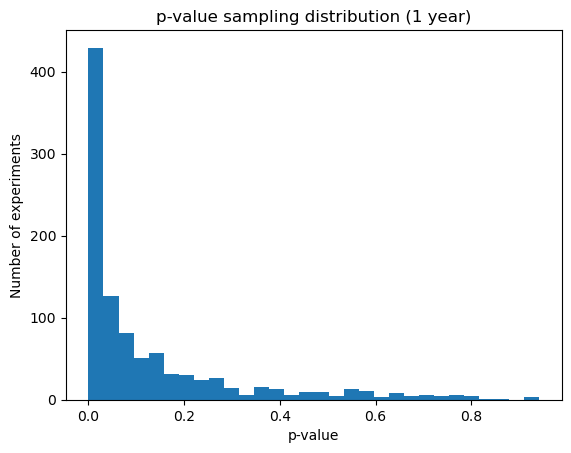

Mean p-value: 0.12832878794530972


In [8]:

plt.hist(p_values, bins=30)

plt.xlabel("p-value")
plt.ylabel("Number of experiments")
plt.title("p-value sampling distribution (1 year)")
plt.show()

mean_p = np.mean(p_values)

print("Mean p-value:", mean_p)


1 years: mean p = 1.2568e-01
2 years: mean p = 2.1698e-02
3 years: mean p = 3.0320e-03
4 years: mean p = 3.6168e-04
5 years: mean p = 3.5966e-05
6 years: mean p = 3.8284e-06
7 years: mean p = 3.8157e-07
8 years: mean p = 2.5070e-08
9 years: mean p = 2.3842e-09
10 years: mean p = 2.7264e-11


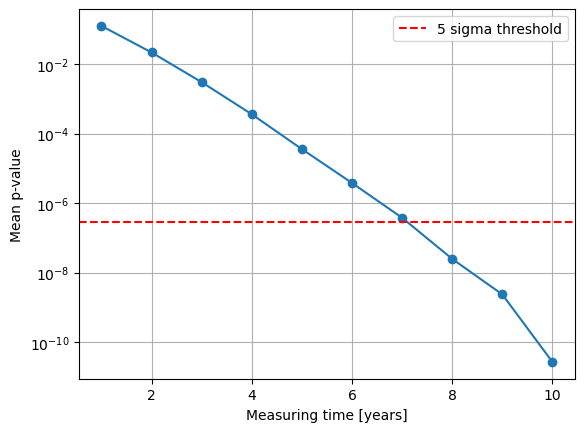

Required whole years: 8


In [9]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, chi2

rng = np.random.default_rng(42)

# Physical parameters
alpha = 0.0218
mu = 126.5
sigma = 2.0

rate_signal = 400
rate_background = 80000

edges = np.linspace(100, 140, 21)

# Background probabilities for each bin
p_background = (
    np.exp(-alpha * (edges[:-1] - 100))
    - np.exp(-alpha * (edges[1:] - 100))
) / (1 - np.exp(-alpha * 40))

# Gaussian signal probabilities for each bin
p_signal = (
    norm.cdf(edges[1:], loc=mu, scale=sigma)
    - norm.cdf(edges[:-1], loc=mu, scale=sigma)
)

# Monte Carlo simulation for T years
def simulate(T, n_experiments=100000):

    # Expected bin counts under H0
    expected = rate_background * T * p_background

    # Mean bin counts when Higgs exists
    mean_observed = (
        expected + rate_signal * T * p_signal
    )

    # Generate many independent experiments
    observed = rng.poisson(
        mean_observed,
        size=(n_experiments, 20)
    )

    # Pearson chi-square for each experiment
    chi2_values = np.sum(
        (observed - expected)**2 / expected,
        axis=1
    )

    # p-values under the null hypothesis
    p_values = chi2.sf(chi2_values, df=20)

    return np.mean(p_values), p_values


# Simulate different measuring times
years = np.arange(1, 11)
mean_p_values = []

for T in years:
    mean_p, _ = simulate(T)
    mean_p_values.append(mean_p)
    print(f"{T} years: mean p = {mean_p:.4e}")

mean_p_values = np.array(mean_p_values)

# Plot
threshold = 2.9e-7

plt.semilogy(years, mean_p_values, "o-")
plt.axhline(
    threshold,
    color="red",
    linestyle="--",
    label="5 sigma threshold"
)

plt.xlabel("Measuring time [years]")
plt.ylabel("Mean p-value")
plt.legend()
plt.grid(True)
plt.show()

# First integer year reaching the threshold
valid = years[mean_p_values < threshold]

if len(valid) > 0:
    print("Required whole years:", valid[0])
else:
    print("Extend the simulated time range")


1 years: 0.14%
2 years: 4.11%
3 years: 23.14%
4 years: 54.83%
5 years: 81.30%
6 years: 94.43%
7 years: 98.76%
8 years: 99.79%
9 years: 99.97%
10 years: 100.00%


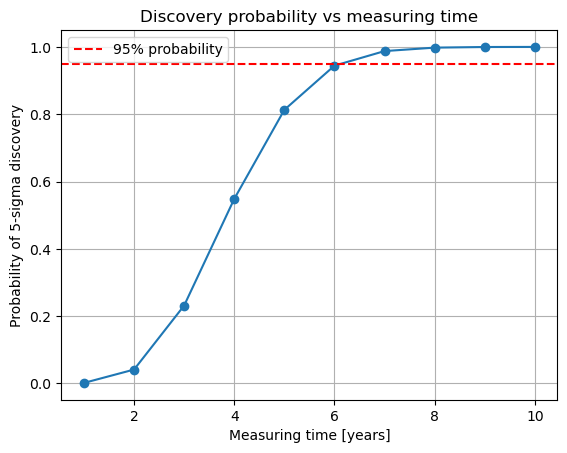

Required years: 7


In [10]:

# Task 3: 95% probability of reaching 5 sigma

threshold = 2.9e-7
power_values = []

for T in years:

    # Simulate experiments for T years
    mean_p, p_values = simulate(T, n_experiments=100000)

    # Fraction of experiments reaching 5 sigma
    power = np.mean(p_values < threshold)

    power_values.append(power)

    print(f"{T} years: {power * 100:.2f}%")

power_values = np.array(power_values)

# Plot discovery probability
plt.plot(years, power_values, "o-")

plt.axhline(
    0.95,
    color="red",
    linestyle="--",
    label="95% probability"
)

plt.xlabel("Measuring time [years]")
plt.ylabel("Probability of 5-sigma discovery")
plt.title("Discovery probability vs measuring time")
plt.legend()
plt.grid(True)
plt.show()

# First full year with at least 95% probability
valid = years[power_values >= 0.95]

if len(valid) > 0:
    print("Required years:", valid[0])
else:
    print("Extend the simulated time range")
